# Image Classifier Project

#### Step 1: Data collection

In [1]:
# Import Packages
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

In [2]:
import warnings 
warnings.filterwarnings('ignore')

In [3]:
from tensorflow import keras
from keras.preprocessing import image

2025-06-06 00:37:04.696889: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-06-06 00:37:05.079524: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-06-06 00:37:05.286371: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-06-06 00:37:05.591102: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-06-06 00:37:05.650045: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-06-06 00:37:06.167416: I tensorflow/core/platform/cpu_feature_gu

In [4]:
# Import and Check first 9 Dog Pictures
# Path to the directory containing your image data
image_folder = '../data/raw/train'

In [5]:
# Get a list of all dog image file names
dog_images = [f for f in os.listdir(image_folder) if f.startswith('dog')][:9]

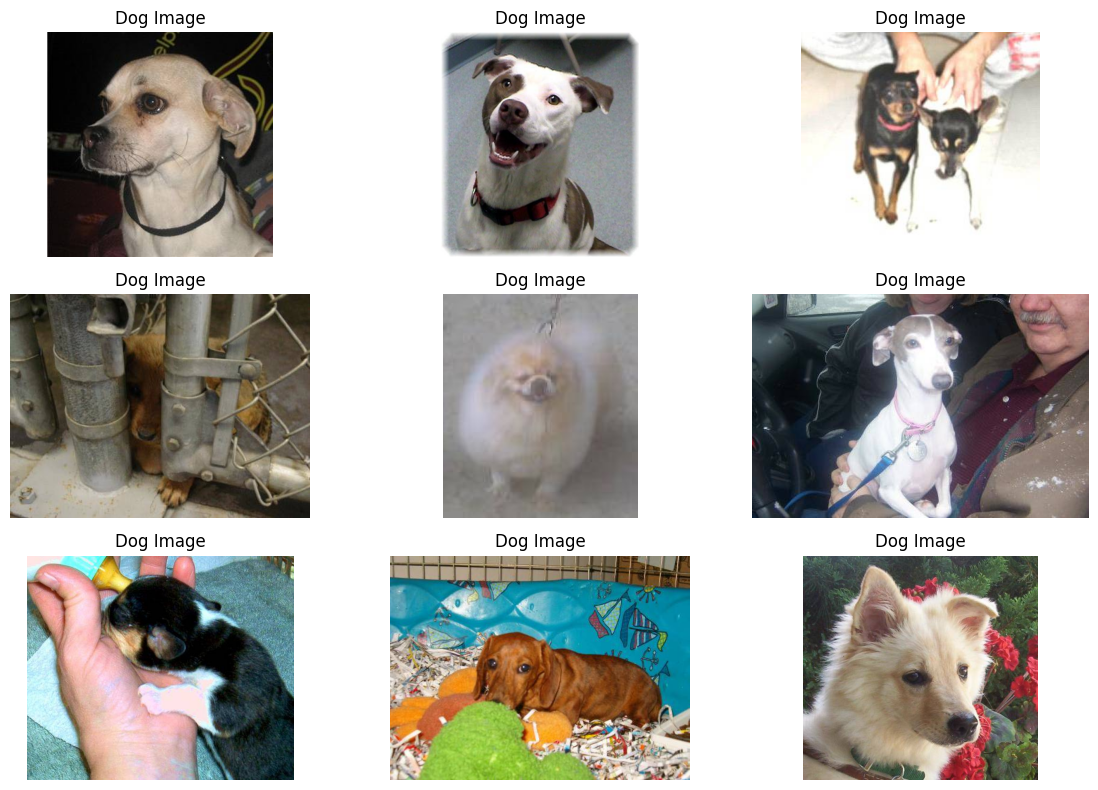

In [6]:
# Create a single figure to display all nine images
plt.figure(figsize=(12, 8))

for i, fname in enumerate(dog_images):
    img = mpimg.imread(os.path.join(image_folder, fname))
    plt.subplot(3, 3, i+1)
    plt.imshow(img)
    plt.title("Dog Image")
    plt.axis('off')

# Adjust Layout
plt.tight_layout()

# Show the pictures
plt.show()

In [7]:
# Get a list of all cat image file names
cat_images = [f for f in os.listdir(image_folder) if f.startswith('cat')][:9]

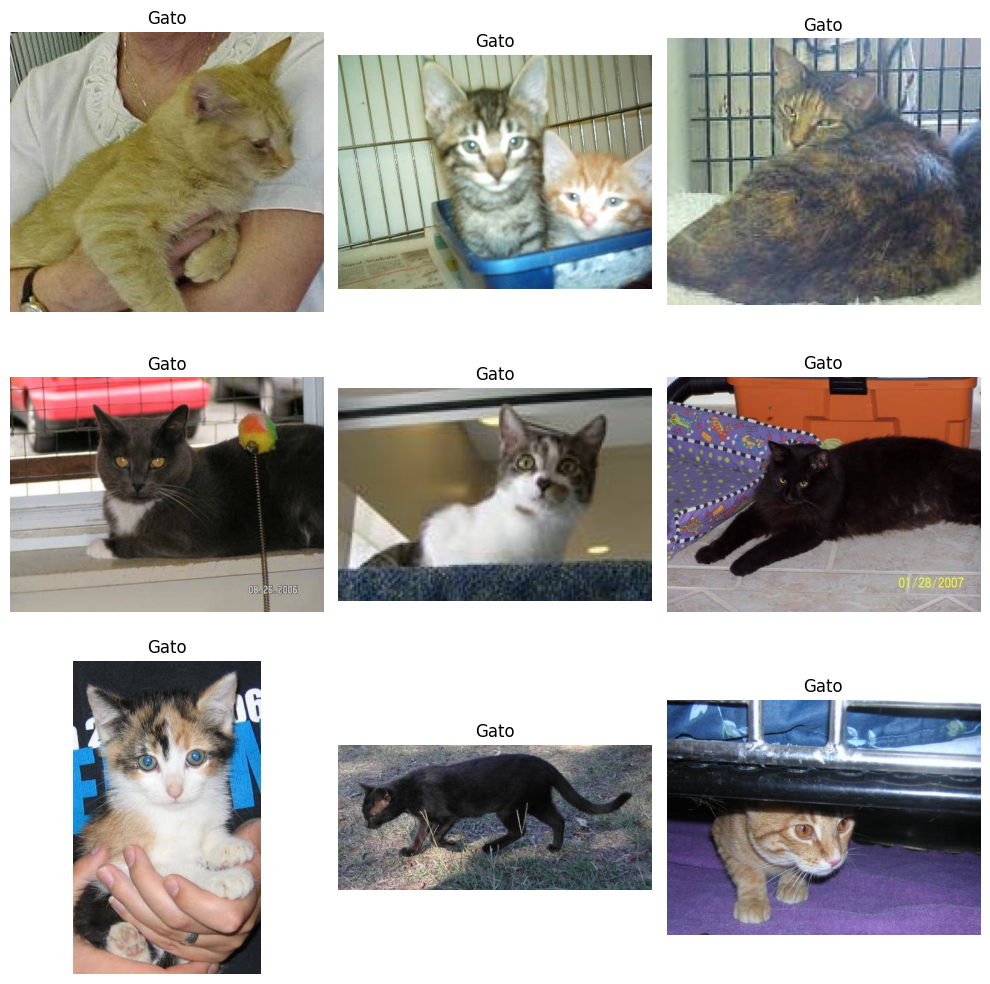

In [8]:
# Create a single figure to display all nine images
plt.figure(figsize=(10, 10))
for i, fname in enumerate(cat_images):
    img = mpimg.imread(os.path.join(image_folder, fname))
    plt.subplot(3, 3, i+1)
    plt.imshow(img)
    plt.title("Gato")
    plt.axis('off')

# Adjust Layout
plt.tight_layout()

# Show the pictures
plt.show()

In [ ]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array

data = []
labels = []

for fname in os.listdir(image_folder):
    label = 1 if fname.startswith('dog') else 0
    path = os.path.join(image_folder, fname)
    image = load_img(path, target_size=(200, 200))
    image = img_to_array(image)
    data.append(image)
    labels.append(label)

# Convertir a arrays
data = np.array(data, dtype="float32") / 255.0
labels = np.array(labels)
print("Tamaño del dataset cargado:", data.shape)

In [1]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPool2D, Flatten, Dense
from tensorflow.keras.optimizers import Adam

2025-06-06 00:49:04.286253: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-06-06 00:49:04.567991: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-06-06 00:49:04.748619: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-06-06 00:49:05.058305: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-06-06 00:49:05.146869: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-06-06 00:49:05.558917: I tensorflow/core/platform/cpu_feature_gu

In [2]:
model = Sequential()
model.add(Conv2D(input_shape = (224,224,3), filters = 64, kernel_size = (3,3), padding = "same", activation = "relu"))
model.add(Conv2D(filters = 64,kernel_size = (3,3),padding = "same", activation = "relu"))
model.add(MaxPool2D(pool_size = (2,2),strides = (2,2)))

model.add(Conv2D(filters = 128, kernel_size = (3,3), padding = "same", activation = "relu"))
model.add(Conv2D(filters = 128, kernel_size = (3,3), padding = "same", activation = "relu"))
model.add(MaxPool2D(pool_size = (2,2),strides = (2,2)))

model.add(Conv2D(filters = 256, kernel_size = (3,3), padding = "same", activation = "relu"))
model.add(Conv2D(filters = 256, kernel_size = (3,3), padding = "same", activation = "relu"))
model.add(Conv2D(filters = 256, kernel_size = (3,3), padding = "same", activation = "relu"))
model.add(MaxPool2D(pool_size = (2,2),strides = (2,2)))

model.add(Conv2D(filters = 512, kernel_size = (3,3), padding = "same", activation = "relu"))
model.add(Conv2D(filters = 512, kernel_size = (3,3), padding = "same", activation = "relu"))
model.add(Conv2D(filters = 512, kernel_size = (3,3), padding = "same", activation = "relu"))
model.add(MaxPool2D(pool_size = (2,2),strides = (2,2)))

model.add(Conv2D(filters = 512, kernel_size = (3,3), padding = "same", activation = "relu"))
model.add(Conv2D(filters = 512, kernel_size = (3,3), padding = "same", activation = "relu"))
model.add(Conv2D(filters = 512, kernel_size = (3,3), padding = "same", activation = "relu"))
model.add(MaxPool2D(pool_size = (2,2),strides = (2,2)))

model.add(Flatten())
model.add(Dense(units = 4096,activation = "relu"))
model.add(Dense(units = 4096,activation = "relu"))
model.add(Dense(units = 2, activation = "softmax"))

/home/vscode/.local/lib/python3.11/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2025-06-06 00:49:59.271659: W external/local_tsl/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 411041792 exceeds 10% of free system memory.
2025-06-06 00:49:59.956194: W external/local_tsl/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 411041792 exceeds 10% of free system memory.
2025-06-06 00:50:00.119111: W external/local_tsl/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 411041792 exceeds 10% of free system memory.


In [3]:
model.compile(
    loss='sparse_categorical_crossentropy',  # Porque usas 2 clases codificadas como 0 y 1
    optimizer=Adam(learning_rate=0.0001),
    metrics=['accuracy']
)

In [ ]:
history = model.fit(
    trdata,
    validation_data=tsdata,
    epochs=10,
    steps_per_epoch=len(trdata),
    validation_steps=len(tsdata)
)

In [ ]:
from sklearn.model_selection import train_test_split

# Dividir en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(data, labels, test_size=0.2)

history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=10,
    batch_size=32
)

In [ ]:
# Evaluar en el conjunto de prueba
loss, acc = model.evaluate(X_test, y_test)
print(f"Precisión en el conjunto de prueba: {acc*100:.2f}%")